In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_gaussian_quantiles
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor

In [2]:
rand = 42
sample_amount = 40_000
feature_amount = 20

In [4]:
#dataset 1 (8 blobs)

X, cluster_id = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=8, cluster_std=1.2, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [4]:
#dataset 2 (1 cluster with correlated features)

mean = np.zeros(feature_amount)
cov = np.random.default_rng(rand).uniform(-0.5, 0.5, size=(feature_amount, feature_amount))
cov = cov @ cov.T
X = np.random.default_rng(rand).multivariate_normal(mean, cov, size=sample_amount)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [28]:
#dataset 3 (nested/ non-linear structure)

X, y = make_gaussian_quantiles(n_samples=sample_amount, n_features=feature_amount, n_classes=3, random_state=rand)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [5]:
#1 | extreme        | push feature values far outside range
#2 | gaussian       | add jitter to feature values
#3 | shuffle        | swap feature values with other row's
#4 | uniform_random | replace feature values with values from data range (ignores correlation)

#IMPORTANT: WHEN ADDING NOISE MORE THAN ONCE, CHANGE THE SEED OR IT WILL CHOOSE SAME COLUMNS TO ADD NOISE TOO AND OVERIDE PREVIOUS NOISE ADDITIONS

def inject_noise(df, noise_frac=0.1, method=1, n_features_affected=None, seed=rand, mask=None):

    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    if mask is None:
        mask = np.zeros(n, dtype=bool)
    mask[df.index.get_indexer(noise_idx)] = True

    for row_id in noise_idx:
        if n_features_affected is None:
            cols = cols_all
        else:
            cols = rng.choice(cols_all, size=n_features_affected, replace=False)

        for col in cols:
            std = df[col].std()

            match method:
                case 1:
                    direction = rng.choice([-1, 1])
                    magnitude = rng.uniform(6, 12)
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * std * magnitude

                case 2:
                    noisy.loc[row_id, col] = df.loc[row_id, col] + rng.normal(0, std * 3)

                case 3:
                    donor_id = rng.choice(df.index)
                    noisy.loc[row_id, col] = df.loc[donor_id, col]

                case 4:
                    lo, hi = df[col].min(), df[col].max()
                    noisy.loc[row_id, col] = rng.uniform(lo, hi)

                case _:
                    raise ValueError(f"Unknown method: {method}")

    return noisy, mask

In [6]:
noisy_df, true_mask = inject_noise(df, noise_frac=0.1, method=1)

In [39]:
print(len(np.array(np.where(true_mask == True)).reshape(-1))/len(true_mask))

0.28


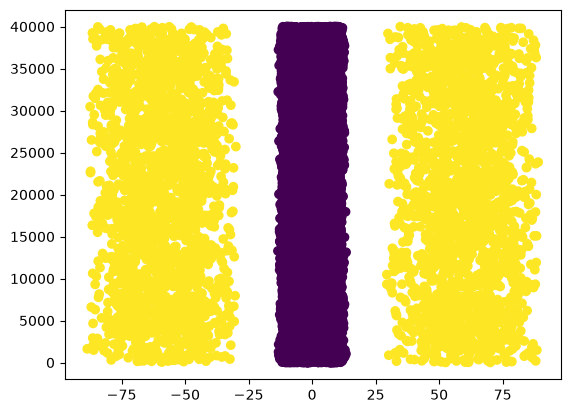

In [7]:
plt.scatter(noisy_df.iloc[:, 0], df.index, c=true_mask)
plt.scatter
plt.show()

In [26]:
#metaparam
iqr_fence = 1.5
iqr_col_ratio = 0.8
isof_estimators = 200
kmeans_clusters = 8
kmeans_init = 20
kmeans_contam = 0.1
dbscan_eps = 3
dbscan_min_samp = 40
lof_neighbors = 50

def run_iqr(data, mask=None):
    suspects = np.zeros(len(data), dtype=int)
    for col in data.columns:
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        suspects += (data[col] < lower) | (data[col] > upper)
    flagged = (suspects > len(data.columns) * iqr_col_ratio).to_numpy()
    print(f"IQR: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"]))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_isolation_forest(data, mask=None):
    model = IsolationForest(n_estimators=isof_estimators, contamination='auto', n_jobs=-1, random_state=rand)
    flagged = model.fit_predict(data) == -1
    print(f"ISOLATION FOREST: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"]))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_kmeans(data, mask=None):
    scaled = StandardScaler().fit_transform(data)
    kmeans = KMeans(n_clusters=kmeans_clusters, random_state=rand, n_init=kmeans_init)
    kmeans.fit(scaled)
    distances = np.min(kmeans.transform(scaled), axis=1)
    threshold = np.percentile(distances, (1 - kmeans_contam) * 100)
    flagged = distances > threshold
    print(f"K MEANS: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"]))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_dbscan(data, mask=None):
    scaled = StandardScaler().fit_transform(data)
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samp, n_jobs=-1)
    flagged = dbscan.fit_predict(scaled) == -1
    print(f"DBSCAN: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"]))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_lof(data, mask=None):
    scaled = StandardScaler().fit_transform(data)
    lof = LocalOutlierFactor(n_neighbors=lof_neighbors, contamination='auto')
    flagged = lof.fit_predict(scaled) == -1
    print(f"LOF: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"]))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

In [24]:
data = noisy_df.copy()
mask = true_mask.copy()
data = run_iqr(data)

IQR: 
entries remaining: 36000
entries flagged: 4000


In [28]:
data = noisy_df.copy()
mask = true_mask.copy()

data = run_iqr(data)
data = run_isolation_forest(data)
data = run_kmeans(data)
data = run_dbscan(data)
data = run_lof(data)

IQR: 
entries remaining: 36000
entries flagged: 4000
ISOLATION FOREST: 
entries remaining: 31983
entries flagged: 4017
K MEANS: 
entries remaining: 28784
entries flagged: 3199
DBSCAN: 
entries remaining: 28784
entries flagged: 0
LOF: 
entries remaining: 28784
entries flagged: 0
